# Tutorial 1: Postage Stamp Extraction, Sub-pixel Alignment, Moffat Subtraction, and Spike-Preserving Masking

In this tutorial, you will learn the fundamental preprocessing steps for measuring the extended Point Spread Function (ePSF) of the Roman Space Telescope:

1. **Adaptive Postage Stamp Extraction**: Dynamically sizing cutouts based on stellar brightness tiers (**Bright**, **Medium**, and **Faint**) to capture optical wings and diffraction spikes without excessive memory overhead.
2. **Sub-pixel Centering & Alignment**: Aligning stellar centroids to the exact sub-pixel grid center to prevent artificial smearing of the PSF core and diffraction spikes.
3. **Background Subtraction**: Robust estimation of local background flux in peripheral annuli.
4. **2D Moffat Pre-fitting & Subtraction**: Fitting an analytical 2D Moffat profile to isolate the smooth central star light from extraneous contaminants.
5. **Dual-Prior Diffraction Spike Protection**:
   - **Theoretical 6-fold pupil geometry priors**: Angular cones calculated from Roman's secondary mirror spider angles (`[23.55, 55.29, 80.25, 118.65, 142.88, 178.07]°`) rotated by aperture position angle.
   - **Morphological ridge detection**: High-aspect-ratio directional filtering on Moffat residuals.
6. **Non-Star Contaminant Masking**: Segmenting background galaxies and neighboring stars on the residual map while **strictly protecting the 6-fold diffraction spikes and stellar wings** from being masked.
7. **Interactive Tier Exploration**: Easily switch between **Bright**, **Medium**, and **Faint** stars or compare them side-by-side.


In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, SymLogNorm

# Add romanepsf to path if running in notebooks directory
if ".." not in sys.path:
    sys.path.insert(0, "..")

import romanepsf as rep

print(f"romanepsf version: {rep.__version__}")


romanepsf version: 0.1.0


## Step 1: Load Roman Level 2 Dataset and Stellar Catalog

We load the simulated commissioning Level 2 dataset for detector `wfi01` (PID 1083) and the pre-filtered, tiered stellar catalog.

In [2]:
# Paths to dataset and configuration
l2_path = "/Users/pmsanch1/storage/ROMAN/simulated_comissioning/PID1083/detectors/r0108301001001001001_0001_wfi01_f146_cal.asdf"
catalog_path = "../output/run_all/wfi01_stars_tiered.csv"
config_path = "../configs/default.yaml"

# Load config and calibrated Level 2 data
cfg = rep.load_config(config_path)
l2 = rep.load_l2_image(l2_path, calibrate=True)
stars_df = pd.read_csv(catalog_path)

print(f"Detector: {l2.detector} | Filter: {l2.filter_name}")
print(f"Science image shape: {l2.data.shape} | Pixel scale: {l2.pixel_scale:.4f} arcsec/pixel")
print(f"Total stars on {l2.detector}: {len(stars_df)}")
display(stars_df[["source_id", "tier", "mag_lambda", "peak_flux", "x", "y"]])


Detector: WFI01 | Filter: F146
Science image shape: (4088, 4088) | Pixel scale: 0.1092 arcsec/pixel
Total stars on WFI01: 5


,source_id,tier,mag_lambda,peak_flux,x,y
0,6854433763338516992,bright,10.437789,4684.790527,2597.956974,3729.937092
1,6854434484893040896,medium,11.651106,4954.201172,2410.641583,1998.029202
2,6866443557049402112,medium,12.322636,4045.300537,1221.483642,3413.698848
3,6866444003726023808,faint,13.934746,3424.432861,113.600024,2021.873857
4,6866443831927325312,faint,13.982554,2360.815918,157.744096,2737.821396


## Step 2: Choose Stellar Brightness Tier

Set `SELECTED_TIER` to `'bright'`, `'medium'`, or `'faint'` below. 
- **Bright stars** ($m < 11.0$): Trace the extended PSF wings and 6-fold diffraction spikes out to large radii ($r > 20''$). The core is saturated.
- **Medium stars** ($11.0 \le m < 13.0$): Transition stars used for cross-tier overlap flux normalization.
- **Faint stars** ($m \ge 13.0$): Unsaturated core stars ($r < 1.5''$).

In [3]:
# >>> SELECT TIER HERE <<<
# Options: 'bright', 'medium', 'faint'
SELECTED_TIER = "bright"

tier_candidates = stars_df[stars_df["tier"] == SELECTED_TIER].reset_index(drop=True)
print(f"Available '{SELECTED_TIER}' stars on {l2.detector}: {len(tier_candidates)}")

# Select first candidate in this tier
target_star = tier_candidates.iloc[0]
print(f"Selected Star ID: {target_star['source_id']}")
print(f"  Coordinates: RA={target_star['ra']:.5f}°, Dec={target_star['dec']:.5f}°")
print(f"  Pixel position: ({target_star['x']:.2f}, {target_star['y']:.2f})")
print(f"  Magnitude (F146): {target_star['mag_lambda']:.2f} | Peak flux: {target_star['peak_flux']:.1f} DN/s")


Available 'bright' stars on WFI01: 1
Selected Star ID: 6854433763338516992
  Coordinates: RA=303.19592°, Dec=-20.02567°
  Pixel position: (2597.96, 3729.94)
  Magnitude (F146): 10.44 | Peak flux: 4684.8 DN/s


## Step 3: Adaptive Postage Stamp Extraction

Stamp sizes are adaptively scaled based on the expected PSF extension to adequately capture all relevant features without excessive memory consumption.

In [4]:
# 1. Determine adaptive cutout size
stamp_sz = rep.get_adaptive_stamp_size(
    mag=target_star["mag_lambda"],
    tier=SELECTED_TIER,
    max_size=cfg.stamps.sizes.bright_max,
    pixel_scale=l2.pixel_scale,
)
print(f"Calculated adaptive cutout size: {stamp_sz} x {stamp_sz} pixels ({stamp_sz * l2.pixel_scale:.1f} x {stamp_sz * l2.pixel_scale:.1f} arcsec)")

# 2. Extract raw cutout and data quality (DQ) mask
center_xy = (float(target_star["x"]), float(target_star["y"]))
dq_bad = rep.get_dq_mask(l2.dq, cfg.stamps.dq_flags_to_mask)

raw_stamp, (ix, iy) = rep.extract_cutout(l2.data, center_xy, stamp_sz, fill_value=np.nan)
raw_dq, _ = rep.extract_cutout(dq_bad.astype(np.uint8), center_xy, stamp_sz, fill_value=1)
raw_dq = raw_dq.astype(bool)

print(f"Extracted integer grid center: ({ix}, {iy})")
print(f"Sub-pixel centroid offset: dx={center_xy[0] - ix:+.3f} px, dy={center_xy[1] - iy:+.3f} px")


Calculated adaptive cutout size: 1001 x 1001 pixels (109.3 x 109.3 arcsec)
Extracted integer grid center: (2598, 3730)
Sub-pixel centroid offset: dx=-0.043 px, dy=-0.063 px


## Step 4: Sub-pixel Centering & Alignment

To ensure high-precision stacking without blurring the PSF core or diffraction spikes, the stamp is shifted by the sub-pixel fractional offset `(dx, dy)` using bicubic interpolation.

In [5]:
subpixel_offset = (center_xy[0] - ix, center_xy[1] - iy)
aligned_data, aligned_mask = rep.recenter_and_align_stamp(raw_stamp, raw_dq, subpixel_offset)

# Estimate and subtract local background
bkg_val, bkg_rms = rep.estimate_stamp_background(aligned_data, aligned_mask)
aligned_sub = rep.subtract_stamp_background(aligned_data, bkg_val)

print(f"Estimated local background: {bkg_val:.3f} MJy/sr (RMS: {bkg_rms:.3f})")
print(f"Aligned stamp shape: {aligned_sub.shape}")


Estimated local background: 0.402 MJy/sr (RMS: 0.015)
Aligned stamp shape: (1001, 1001)


## Step 5: 2D Moffat Pre-fitting & Residual Subtraction

We fit an analytical 2D Moffat profile to the central core. Subtracting this model from the observation yields the residual map:
$$\Delta I(x, y) = I_{\text{obs}}(x, y) - I_{\text{moffat}}(x, y)$$

On this residual map, external contaminants (background galaxies, field stars) stand out as isolated positive islands, while the smooth stellar profile is removed.

In [6]:
# Fit 2D Moffat model to star core
moffat_img, fitted_model = rep.fit_moffat_model(aligned_sub, dq_mask=aligned_mask)
residual = aligned_sub - moffat_img

print("Fitted Moffat Model Parameters:")
if hasattr(fitted_model, "amplitude"):
    print(f"  Amplitude: {fitted_model.amplitude.value:.2f}")
    print(f"  Gamma (FWHM scale): {fitted_model.gamma.value:.2f} pixels")
    print(f"  Alpha (power index): {fitted_model.alpha.value:.2f}")


Fitted Moffat Model Parameters:
  Amplitude: 22242.15
  Gamma (FWHM scale): 2.07 pixels
  Alpha (power index): 1.56


## Step 6: Dual-Prior Diffraction Spike Protection & Contaminant Masking

Roman's secondary mirror spider assembly and pupil geometry produce two distinct sets of 12-spike diffraction patterns (24 rays total):
1. **Primary First-Order Spikes (Brightest)**: Generated by the 6 primary spider struts at base angles `[12.72, 48.72, 73.22, 106.72, 133.22, 168.22]°`.
2. **Secondary Second-Order Spikes**: Generated by the spider strut edges and pupil facets at base angles `[23.55, 55.29, 80.25, 118.65, 142.88, 178.07]°`.

To strictly protect genuine spikes while allowing complete flexibility for field distortion and SCA clocking, the pipeline combines:
- **Theoretical Dual-Set Priors**: All 24 spike rays rotated by the telescope aperture PA (`roll_ref ≈ -110.02°`) and detector alignment offset (`-9.70°`).
- **Empirical Angle Refinement**: High-speed radial line flux maximization snapping each candidate ray to the observed ridge peak within $\pm 3.5^\circ$.
- **Morphological Residual Ridge Filtering**: Continuous high-aspect-ratio feature detection on Moffat residuals.

Any pixel within this combined spike protection zone is **strictly excluded** from the contaminant mask.

In [ ]:
# Apply dual-prior spike protection & non-star contaminant masking
pa_aperture = l2.meta.get("roll_ref", -110.02)
cfg.spikes.spike_width_px = 8

final_mask, protected_spikes, res_map = rep.mask_contaminants_with_spikes_protected(
    aligned_sub,
    dq_mask=aligned_mask,
    pa_aperture=pa_aperture,
    cfg=cfg.spikes,
    tier=SELECTED_TIER,
)

# Create cleaned stamp with bad/contaminant pixels set to NaN
cleaned_stamp = aligned_sub.copy()
cleaned_stamp[final_mask] = np.nan

print(f"Total pixels in stamp: {aligned_sub.size}")
print(f"Protected spike & core pixels: {np.sum(protected_spikes):,} ({100*np.sum(protected_spikes)/aligned_sub.size:.1f}%)")
print(f"Masked contaminant pixels: {np.sum(final_mask):,} ({100*np.sum(final_mask)/aligned_sub.size:.1f}%)")
print(f"Check: Contaminant overlap inside protected spikes: {np.sum(final_mask & protected_spikes & ~aligned_mask)} (MUST BE 0)")


Total pixels in stamp: 1002001
Protected spike & core pixels: 102,205 (10.2%)
Masked contaminant pixels: 231,188 (23.1%)
Check: Contaminant overlap inside protected spikes: 0 (MUST BE 0)


4.0

## Step 7: Comprehensive 6-Panel Diagnostic Visualization

We display the full progression from raw aligned stamp to final spike-preserved clean cutout.

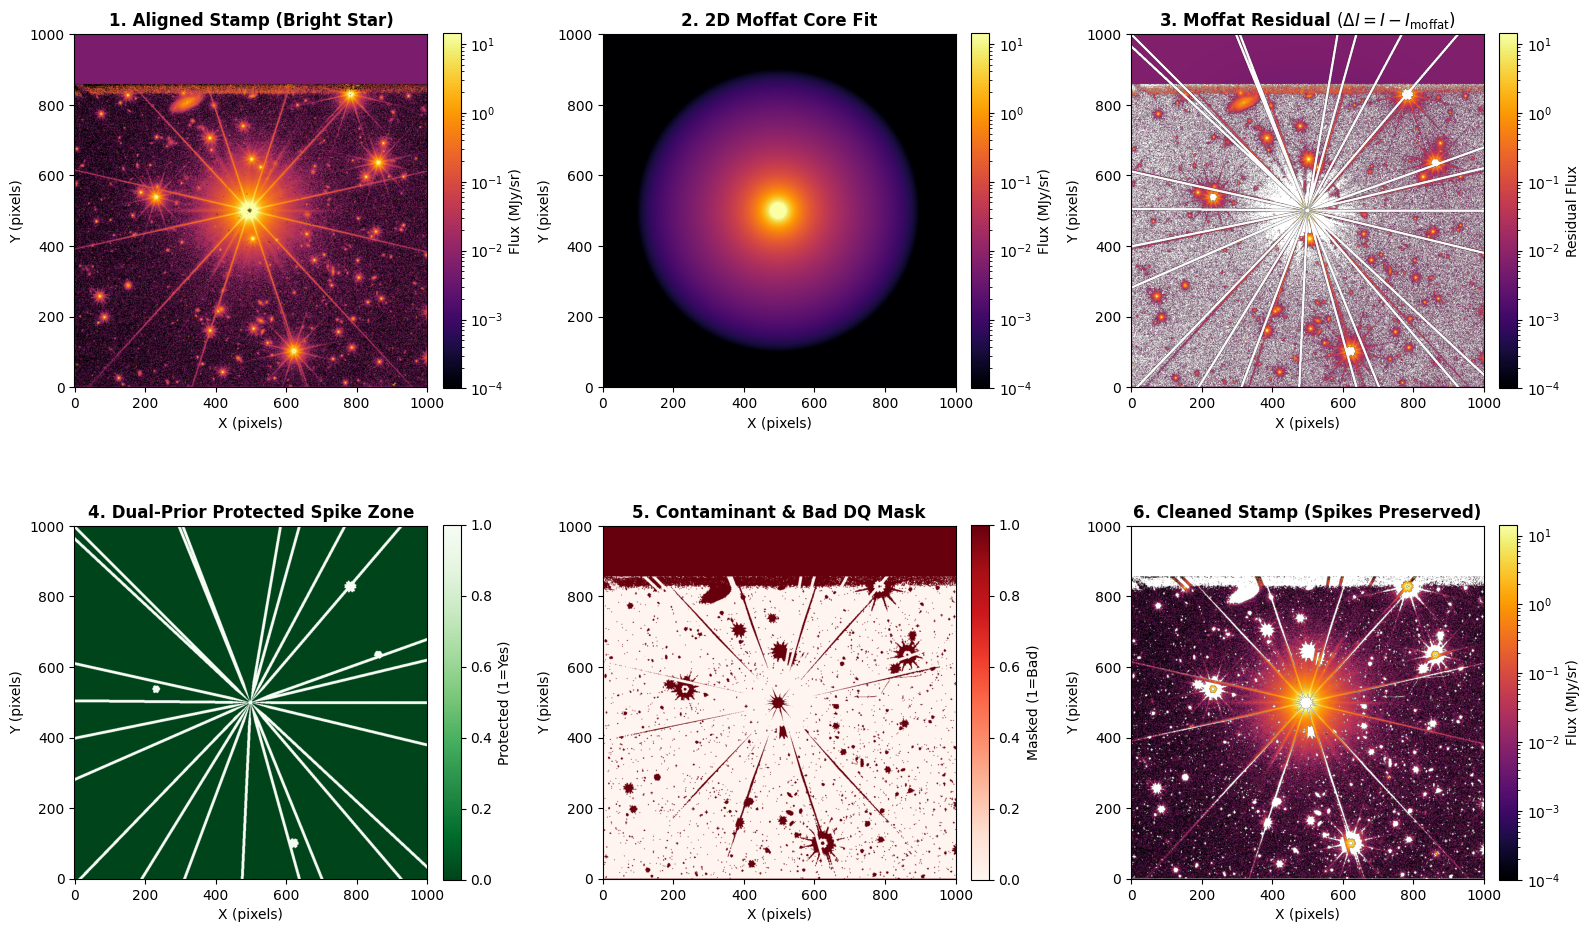

In [8]:
%matplotlib inline
import copy
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

cmap = copy.copy(plt.get_cmap('Purples'))
cmap.set_bad(alpha=0.0)  #
transparent_nan = protected_spikes.astype(float)
transparent_nan[transparent_nan == 0] = np.nan

# Normalize display
vmax = np.nanpercentile(aligned_sub, 99.8)
vmin = max(np.nanpercentile(aligned_sub, 5), 1e-4)

# Panel 1: Aligned star stamp
im1 = axes[0, 0].imshow(np.maximum(aligned_sub, 1e-4), origin="lower", cmap="inferno", norm=LogNorm(vmin=vmin, vmax=vmax))
axes[0, 0].set_title(f"1. Aligned Stamp ({SELECTED_TIER.capitalize()} Star)", fontsize=12, fontweight="bold")
axes[0, 0].set_xlabel("X (pixels)")
axes[0, 0].set_ylabel("Y (pixels)")
plt.colorbar(im1, ax=axes[0, 0], fraction=0.046, pad=0.04, label="Flux (MJy/sr)")

# Panel 2: Fitted 2D Moffat Model
im2 = axes[0, 1].imshow(np.maximum(moffat_img, 1e-4), origin="lower", cmap="inferno", norm=LogNorm(vmin=vmin, vmax=vmax))
axes[0, 1].set_title("2. 2D Moffat Core Fit", fontsize=12, fontweight="bold")
axes[0, 1].set_xlabel("X (pixels)")
axes[0, 1].set_ylabel("Y (pixels)")
plt.colorbar(im2, ax=axes[0, 1], fraction=0.046, pad=0.04, label="Flux (MJy/sr)")

# Panel 3: Moffat Residuals
res_std = np.nanstd(residual)
im3 = axes[0, 2].imshow(residual, origin="lower", cmap="inferno", norm=LogNorm(vmin=vmin, vmax=vmax))
axes[0,2].imshow(transparent_nan, origin="lower", cmap=cmap)
axes[0, 2].set_title("3. Moffat Residual $(\\Delta I = I - I_{\\rm moffat})$", fontsize=12, fontweight="bold")
axes[0, 2].set_xlabel("X (pixels)")
axes[0, 2].set_ylabel("Y (pixels)")
plt.colorbar(im3, ax=axes[0, 2], fraction=0.046, pad=0.04, label="Residual Flux")

# Panel 4: Protected Spike Zone (Dual Prior)
im4 = axes[1, 0].imshow(protected_spikes.astype(int), origin="lower", cmap="Greens_r")
axes[1, 0].set_title("4. Dual-Prior Protected Spike Zone", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("X (pixels)")
axes[1, 0].set_ylabel("Y (pixels)")
plt.colorbar(im4, ax=axes[1, 0], fraction=0.046, pad=0.04, label="Protected (1=Yes)")

# Panel 5: Final Contaminant Mask
im5 = axes[1, 1].imshow(final_mask.astype(int), origin="lower", cmap="Reds")
axes[1, 1].set_title("5. Contaminant & Bad DQ Mask", fontsize=12, fontweight="bold")
axes[1, 1].set_xlabel("X (pixels)")
axes[1, 1].set_ylabel("Y (pixels)")
plt.colorbar(im5, ax=axes[1, 1], fraction=0.046, pad=0.04, label="Masked (1=Bad)")

# Panel 6: Cleaned Stamp for ePSF Stacking
im6 = axes[1, 2].imshow(np.maximum(cleaned_stamp, 1e-4), origin="lower", cmap="inferno", norm=LogNorm(vmin=vmin, vmax=vmax))
axes[1, 2].set_title("6. Cleaned Stamp (Spikes Preserved)", fontsize=12, fontweight="bold")
axes[1, 2].set_xlabel("X (pixels)")
axes[1, 2].set_ylabel("Y (pixels)")
plt.colorbar(im6, ax=axes[1, 2], fraction=0.046, pad=0.04, label="Flux (MJy/sr)")

plt.tight_layout()



## Step 8: Multi-Tier Comparative Gallery (Bright, Medium, Faint)

Here we extract and process one star from each tier simultaneously to compare their morphologies and diffraction features side-by-side.

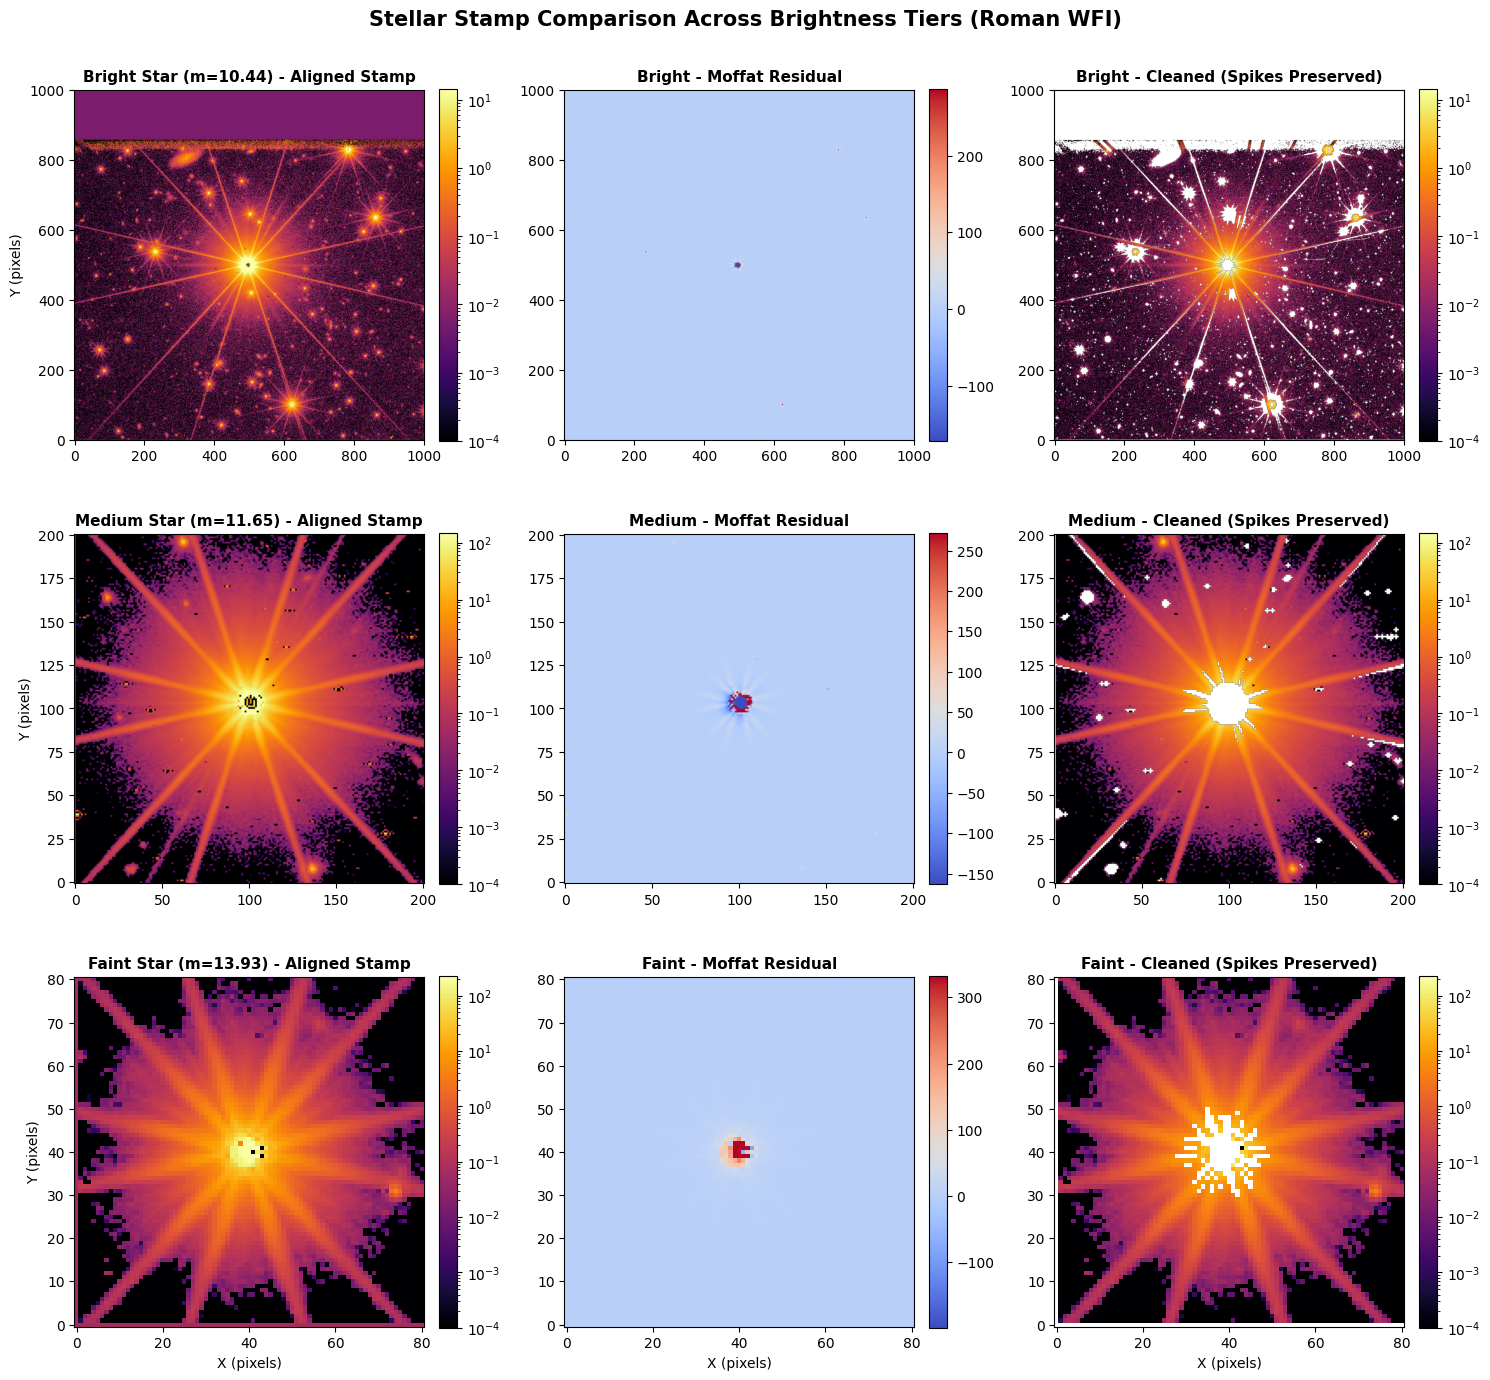

In [10]:
def process_single_star(row, l2_data, config):
    tier = row["tier"]
    mag = row["mag_lambda"]
    cx, cy = float(row["x"]), float(row["y"])
    
    sz = rep.get_adaptive_stamp_size(mag, tier, max_size=config.stamps.sizes.bright_max, pixel_scale=l2_data.pixel_scale)
    raw_stamp, (ix, iy) = rep.extract_cutout(l2_data.data, (cx, cy), sz)
    dq_bad = rep.get_dq_mask(l2_data.dq, config.stamps.dq_flags_to_mask)
    raw_dq, _ = rep.extract_cutout(dq_bad.astype(np.uint8), (cx, cy), sz, fill_value=1)
    
    aligned_data, aligned_mask = rep.recenter_and_align_stamp(raw_stamp, raw_dq.astype(bool), (cx - ix, cy - iy))
    bkg_val, _ = rep.estimate_stamp_background(aligned_data, aligned_mask)
    aligned_sub = rep.subtract_stamp_background(aligned_data, bkg_val)
    
    moffat_img, _ = rep.fit_moffat_model(aligned_sub, dq_mask=aligned_mask)
    residual = aligned_sub - moffat_img
    
    final_mask, protected, _ = rep.mask_contaminants_with_spikes_protected(
        aligned_sub,
        dq_mask=aligned_mask,
        pa_aperture=l2_data.meta.get("roll_ref", -110.02),
        cfg=config.spikes,
        tier=tier
    )
    cleaned = aligned_sub.copy()
    cleaned[final_mask] = np.nan
    return aligned_sub, residual, cleaned

# Process 1 star from each tier
tiers = ["bright", "medium", "faint"]
processed_gallery = {}
for t in tiers:
    cand = stars_df[stars_df["tier"] == t].iloc[0]
    processed_gallery[t] = process_single_star(cand, l2, cfg)

fig, axes = plt.subplots(3, 3, figsize=(15, 14))

for row_idx, t in enumerate(tiers):
    orig, res, clean = processed_gallery[t]
    cand = stars_df[stars_df["tier"] == t].iloc[0]
    
    vmax = np.nanpercentile(orig, 99.8)
    vmin = max(np.nanpercentile(orig, 5), 1e-4)
    res_std = np.nanstd(res)
    
    # Col 1: Original Aligned Stamp
    im1 = axes[row_idx, 0].imshow(np.maximum(orig, 1e-4), origin="lower", cmap="inferno", norm=LogNorm(vmin=vmin, vmax=vmax))
    axes[row_idx, 0].set_title(f"{t.capitalize()} Star (m={cand['mag_lambda']:.2f}) - Aligned Stamp", fontsize=11, fontweight="bold")
    axes[row_idx, 0].set_ylabel("Y (pixels)")
    plt.colorbar(im1, ax=axes[row_idx, 0], fraction=0.046, pad=0.04)
    
    # Col 2: Residuals
    im2 = axes[row_idx, 1].imshow(res, origin="lower", cmap="coolwarm", vmin=-3*res_std, vmax=5*res_std)
    axes[row_idx, 1].set_title(f"{t.capitalize()} - Moffat Residual", fontsize=11, fontweight="bold")
    plt.colorbar(im2, ax=axes[row_idx, 1], fraction=0.046, pad=0.04)
    
    # Col 3: Cleaned Stamp (Spikes Preserved)
    im3 = axes[row_idx, 2].imshow(np.maximum(clean, 1e-4), origin="lower", cmap="inferno", norm=LogNorm(vmin=vmin, vmax=vmax))
    axes[row_idx, 2].set_title(f"{t.capitalize()} - Cleaned (Spikes Preserved)", fontsize=11, fontweight="bold")
    plt.colorbar(im3, ax=axes[row_idx, 2], fraction=0.046, pad=0.04)

axes[2, 0].set_xlabel("X (pixels)")
axes[2, 1].set_xlabel("X (pixels)")
axes[2, 2].set_xlabel("X (pixels)")

plt.suptitle("Stellar Stamp Comparison Across Brightness Tiers (Roman WFI)", fontsize=15, fontweight="bold", y=0.995)
plt.tight_layout()
plt.show()


### Key Observations:
- **Bright Stars**: Clearly show the extended 6-fold diffraction spikes radiating outwards across hundreds of pixels. The core is saturated, but the outer wings and spikes are intact.
- **Medium Stars**: Well-behaved transition stars bridging the core and wings, showing moderate spikes and unsaturated outer cores.
- **Faint Stars**: Completely unsaturated central point source without prominent wings, ideal for determining the core profile shape ($r < 1.5''$).
